# 図形での実験：巡回路長の推定式の検証

## 環境構築

In [1]:
!uv pip install elkai numpy pandas matplotlib shapely tqdm

Checked 6 packages in 83ms


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import shapely
from shapely.geometry import Polygon, LineString, box
from shapely import affinity
from scipy.optimize import least_squares

from elkai import _elkai
from tqdm.auto import tqdm
import os

/Users/hasega60/Dropbox/work/research/00_paper/202610_COR/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
!uv pip show elkai

Name: elkai
Version: 2.0.1
Location: /Users/hasega60/.cache/uv/builds-v0/.tmpFQK232/lib/python3.9/site-packages
Requires:
Required-by:


In [4]:
import platform

print("OS名:", platform.system())
print("OSのバージョン:", platform.release())
print("OSの詳細:", platform.version())
print("アーキテクチャ:", platform.machine())
print("プロセッサ:", platform.processor())
print("論理CPU数:", os.cpu_count())

OS名: Darwin
OSのバージョン: 27.0.0
OSの詳細: Darwin Kernel Version 27.0.0: Tue Aug 11 21:22:49 PDT 2026; root:xnu-13432.1.9~1/RELEASE_ARM64_T6000
アーキテクチャ: x86_64
プロセッサ: i386
論理CPU数: 10


## 設定

In [5]:
N_LIST = [50,75,100,200,300,400,500]
# 各図形の試行回数
REPS = {
        50:1000, 
        75:1000, 
        100:1000, 
        200:200, 
        300:200, 
        400:200, 
        500:200}

# トーラスの試行回数
TORUS_REPS = {
        50:1000, 
        75:1000, 
        100:1000, 
        200:200, 
        300:200, 
        400:200, 
        500:200}

B_REPS=1000

MAX_TRIALS = 100
SCALE = 1e5   # LKH は整数距離なのでスケール変更
rng = np.random.default_rng(0)

## 図形の定義（すべて面積 1）：Calibration と Validation

In [6]:
def normalize(p):
    s = 1 / np.sqrt(p.area)
    p = affinity.scale(p, s, s, origin=(0, 0))
    return affinity.translate(p, -p.centroid.x, -p.centroid.y)

def regular(k):
    t = np.linspace(0, 2 * np.pi, k, endpoint=False) + np.pi / 2
    return Polygon(np.c_[np.cos(t), np.sin(t)])

def ellipse(a, m=4000):
    t = np.linspace(0, 2 * np.pi, m, endpoint=False)
    return Polygon(np.c_[a * np.cos(t), np.sin(t)])

def sector(deg, r_in=0.0, m=2000):   # 扇形（r_in > 0 なら環状の扇形）
    t = np.linspace(0, np.deg2rad(deg), m)
    outer = np.c_[np.cos(t), np.sin(t)]
    inner = np.c_[r_in * np.cos(t[::-1]), r_in * np.sin(t[::-1])] if r_in > 0 else np.array([[0.0, 0.0]])
    return Polygon(np.r_[outer, inner])

CAL = {
    "Circle": ellipse(1.0),
    "Ellipse 4:1": ellipse(4.0),
    "Semicircle": sector(180),
    "Half annulus": sector(180, 0.5),
    "Square": box(0, 0, 1, 1),
    "Triangle": regular(3),
    "Rectangle 3:1": box(0, 0, 1, 3),
    "L-shape": Polygon([(0, 0), (2, 0), (2, 1), (1, 1), (1, 2), (0, 2)]),
    "Cross": Polygon([(1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (2, 2), (2, 3), (1, 3), (1, 2), (0, 2), (0, 1), (1, 1)]),
}
VAL = {
    "Ellipse 2:1": ellipse(2.0),
    "Capsule 3:1": LineString([(-2, 0), (2, 0)]).buffer(1, quad_segs=500),
    "Quarter circle": sector(90),
    "C-shape": sector(270, 0.5),
    "Rectangle 2:1": box(0, 0, 2, 1),
    "Right triangle": Polygon([(0, 0), (1, 0), (0, 1)]),
    "Rectangle 4:1": box(0, 0, 1, 4),
    "U-shape": Polygon([(0, 0), (5, 0), (5, 4), (3.5, 4), (3.5, 1.5), (1.5, 1.5), (1.5, 4), (0, 4)]),
    "T-shape": Polygon([(0, 2), (1, 2), (1, 0), (2, 0), (2, 2), (3, 2), (3, 3), (0, 3)]),
}
CAL = {k: normalize(v) for k, v in CAL.items()}
VAL = {k: normalize(v) for k, v in VAL.items()}
SHAPES = {**CAL, **VAL}

In [7]:
# 分類：境界（curved / polygonal）、角の有無、凸性、細長さ
CURVED = ["Circle", "Ellipse 4:1", "Semicircle", "Half annulus", "Ellipse 2:1", "Capsule 3:1", "Quarter circle", "C-shape"]
NO_CORNER = ["Circle", "Ellipse 4:1", "Ellipse 2:1", "Capsule 3:1"]

def aspect(p):
    x, y = p.minimum_rotated_rectangle.exterior.xy
    e = sorted([np.hypot(x[1] - x[0], y[1] - y[0]), np.hypot(x[2] - x[1], y[2] - y[1])])
    return e[1] / e[0]

pd.DataFrame([{"shape": k, "set": "Calibration" if k in CAL else "Validation",
               "boundary": "curved" if k in CURVED else "polygonal",
               "corners": "no" if k in NO_CORNER else "yes",
               "convex": p.convex_hull.area / p.area < 1.001,
               "elongated": aspect(p) >= 3,
               "S": round(p.length, 2)} for k, p in SHAPES.items()])

,shape,set,boundary,corners,convex,elongated,S
0,Circle,Calibration,curved,no,True,False,3.54
1,Ellipse 4:1,Calibration,curved,no,True,True,4.84
2,Semicircle,Calibration,curved,yes,True,False,4.10
3,Half annulus,Calibration,curved,yes,False,False,5.26
4,Square,Calibration,polygonal,yes,True,False,4.00
5,Triangle,Calibration,polygonal,yes,True,False,4.56
6,Rectangle 3:1,Calibration,polygonal,yes,True,True,4.62
7,L-shape,Calibration,polygonal,yes,False,False,4.62
8,Cross,Calibration,polygonal,yes,False,False,5.37
9,Ellipse 2:1,Validation,curved,no,True,False,3.87


## LKH による巡回路計算

In [8]:
def sample(p, n):
    x0, y0, x1, y1 = p.bounds
    pts = np.empty((0, 2))
    while len(pts) < n:
        c = rng.uniform([x0, y0], [x1, y1], size=(4 * n, 2))
        pts = np.vstack([pts, c[shapely.contains_xy(p, c[:, 0], c[:, 1])]])
    return pts[:n]

def dist_euclid(P):
    return np.sqrt(((P[:, None] - P[None]) ** 2).sum(-1))

def dist_torus(P):
    d = np.abs(P[:, None] - P[None])
    d = np.minimum(d, 1 - d)
    return np.sqrt((d ** 2).sum(-1))

def tour(D):
    M = np.rint(D * SCALE).astype(int)
    problem = ("TYPE : TSP\n"
               f"DIMENSION : {len(D)}\n"
               "EDGE_WEIGHT_TYPE : EXPLICIT\n"
               "EDGE_WEIGHT_FORMAT : FULL_MATRIX\n"
               "EDGE_WEIGHT_SECTION\n"
               + "\n".join(" ".join(map(str, row)) for row in M) + "\n")
    params = f"RUNS = 1\nMAX_TRIALS = {MAX_TRIALS}\nPROBLEM_FILE = :stdin:\n"
    t = np.array(_elkai.solve_problem(params, problem)) - 1
    return np.append(t, t[0])

def tour_length(D):
    t = tour(D)
    return D[t[:-1], t[1:]].sum()

In [9]:
for N in N_LIST:
    filename = f"../output/results_N{N}.json"
    if os.path.exists(filename):
        print(f"{filename} exists")
    else:
        res = {"N": N, "shapes": {}}
        res["shapes"]["Torus"] = {"P": None, "L": [tour_length(dist_torus(rng.random((N, 2)))) for _ in range(TORUS_REPS[N])]}
        for name, p in tqdm(SHAPES.items(), total=len(SHAPES), desc=f"N={N}"):
            res["shapes"][name] = {"P": p.length, "L": [tour_length(dist_euclid(sample(p, N))) for _ in range(REPS[N])]}
        json.dump(res, open(filename, "w"))

../output/results_N50.json exists
../output/results_N75.json exists
../output/results_N100.json exists
../output/results_N200.json exists
../output/results_N300.json exists
../output/results_N400.json exists
../output/results_N500.json exists


## 図形内での巡回路の例（N = 50、1インスタンス）：分類ごとに4段で表示

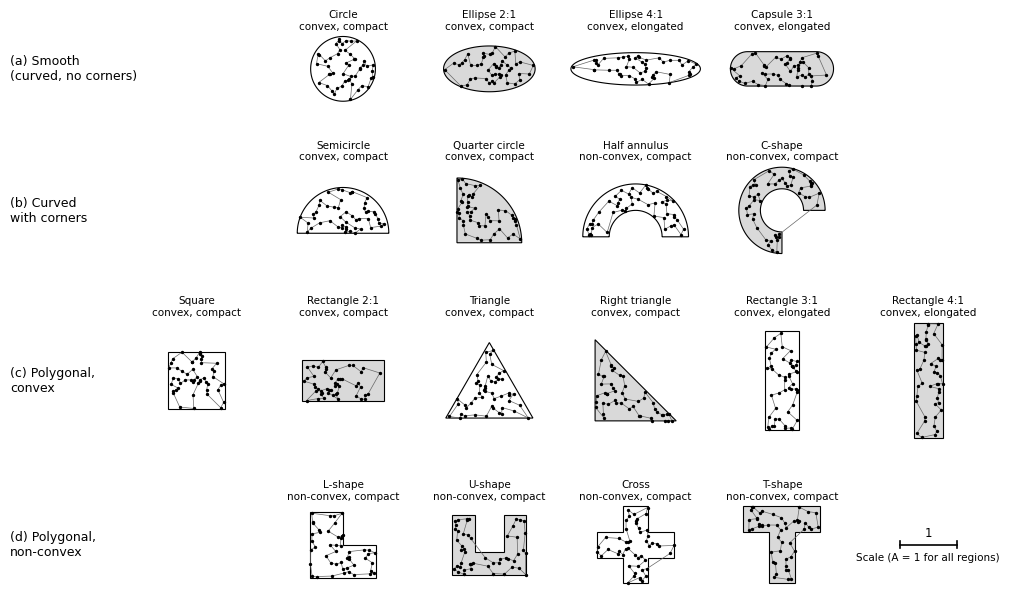

In [10]:
ROWS = [
    ("(a) Smooth\n(curved, no corners)", ["Circle", "Ellipse 2:1", "Ellipse 4:1", "Capsule 3:1"]),
    ("(b) Curved\nwith corners", ["Semicircle", "Quarter circle", "Half annulus", "C-shape"]),
    ("(c) Polygonal,\nconvex", ["Square", "Rectangle 2:1", "Triangle", "Right triangle", "Rectangle 3:1", "Rectangle 4:1"]),
    ("(d) Polygonal,\nnon-convex", ["L-shape", "U-shape", "Cross", "T-shape"]),
]

def tags(p):
    return ("convex" if p.convex_hull.area / p.area < 1.001 else "non-convex") + ", " + ("elongated" if aspect(p) >= 3 else "compact")

ncol = max(len(names) for _, names in ROWS)
HX = 1.25                                                                                   # 横方向の表示範囲（全図形で共通の縮尺）
HY = [max((SHAPES[k].bounds[3] - SHAPES[k].bounds[1]) / 2 for k in names) + 0.08 for _, names in ROWS]   # 段ごとの縦方向の表示範囲
fig = plt.figure(figsize=(10, 6.3))
gs = fig.add_gridspec(4, ncol, height_ratios=HY, left=0.12, right=0.995, top=0.95, bottom=0.05, hspace=0.42, wspace=0.02)
for i, (label, names) in enumerate(ROWS):
    c0 = (ncol - len(names)) // 2
    for j, name in enumerate(names):
        p = SHAPES[name]
        ax = fig.add_subplot(gs[i, c0 + j])
        X = sample(p, 50)
        t = tour(dist_euclid(X))
        x, y = p.exterior.xy
        ax.fill(x, y, color="w" if name in CAL else "0.85", ec="k", lw=0.8)
        ax.plot(X[t, 0], X[t, 1], color="0.4", lw=0.5)
        ax.scatter(X[:, 0], X[:, 1], s=2, color="k", zorder=3)
        ax.set_title(f"{name}\n{tags(p)}", fontsize=7.5, pad=2)
        x0, y0, x1, y1 = p.bounds
        ax.set_xlim((x0 + x1) / 2 - HX, (x0 + x1) / 2 + HX)
        ax.set_ylim((y0 + y1) / 2 - HY[i], (y0 + y1) / 2 + HY[i])
        ax.set_aspect("equal")
        ax.axis("off")
    pos = ax.get_position()
    fig.text(0.005, (pos.y0 + pos.y1) / 2, label, fontsize=9, va="center")
    
ax = fig.add_subplot(gs[3, ncol - 1])   # 縮尺：長さ 1（全図形で A = 1）
ax.plot([-0.5, 0.5], [0, 0], color="k", lw=1.2)
ax.plot([-0.5, -0.5], [-0.06, 0.06], color="k", lw=1.2)
ax.plot([0.5, 0.5], [-0.06, 0.06], color="k", lw=1.2)
ax.text(0, 0.1, "1", ha="center", va="bottom", fontsize=8.5)
ax.text(0, -0.14, "Scale (A = 1 for all regions)", ha="center", va="top", fontsize=7.5)
ax.set_xlim(-HX, HX)
ax.set_ylim(-HY[3], HY[3])
ax.set_aspect("equal")
ax.axis("off")

#fig.text(0.56, 0.005, "White: calibration regions    Grey: validation regions", ha="center", fontsize=8.5)
plt.savefig("../output/fig2_shapes_tours.pdf", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

In [11]:
rows = []

def envelope(p):   # 座標軸に平行な外接長方形：縦横比（長辺/短辺），短辺
    x0, y0, x1, y1 = p.bounds
    W, H = x1 - x0, y1 - y0
    return max(W, H) / min(W, H), min(W, H)

for label, names in ROWS:
    for name in names:
        p = SHAPES[name]
        S_env, W = envelope(p)
        rows.append({"group": label.split(")")[0] + ")", "region": name, "set": "Calibration" if name in CAL else "Validation",
                     "A": p.area, "P": p.length, "S_env": S_env, 
                     #"W": W,
                     "convex": p.convex_hull.area / p.area < 1.001, "elongated": aspect(p) >= 3})
shape_tab = pd.DataFrame(rows).set_index(["group", "region"])   # 予測に用いる指標（A, P, S_P）と分類
display(shape_tab.round(3))

set    A      P  S_env  convex  elongated
group region                                                           
(a)   Circle          Calibration  1.0  3.545  1.000    True      False
      Ellipse 2:1      Validation  1.0  3.865  2.000    True      False
      Ellipse 4:1     Calibration  1.0  4.840  4.000    True       True
      Capsule 3:1      Validation  1.0  4.279  3.000    True       True
(b)   Semicircle      Calibration  1.0  4.102  2.000    True      False
      Quarter circle   Validation  1.0  4.029  1.000    True      False
      Half annulus    Calibration  1.0  5.263  2.000   False      False
      C-shape          Validation  1.0  6.070  1.000   False      False
(c)   Square          Calibration  1.0  4.000  1.000    True      False
      Rectangle 2:1    Validation  1.0  4.243  2.000    True      False
      Triangle        Calibration  1.0  4.559  1.155    True      False
      Right triangle   Validation  1.0  4.828  1.000    True      False
      Rectangle 3:1   Calibration  1.0  4.619  3.000    True       True
      Rectangle 4:1    Validation  1.0  5.000  4.000    True       True
(d)   L-shape         Calibration  1.0  4.619  1.000   False      False
      U-shape          Validation  1.0  5.939  1.250   False      False
      Cross           Calibration  1.0  5.367  1.000   False      False
      T-shape          Validation  1.0  5.367  1.000   False      False

## 各モデルによる結果の比較

### β と γ の推定（Calibration の図形のみ、トーラスとの差分）

In [13]:
L_all = {N: {k: np.array(v["L"]) for k, v in json.load(open(f"../output/results_N{N}.json"))["shapes"].items()} for N in N_LIST}
EL_torus = pd.Series({N: L_all[N]["Torus"].mean() for N in N_LIST})

df = pd.DataFrame([{"N": N, "name": k, "set": "Calibration" if k in CAL else "Validation", "P": p.length, "EL": L_all[N][k].mean()}
                   for N in N_LIST for k, p in SHAPES.items()])
df["dL"] = df.EL - df.N.map(EL_torus)
cal = df[df["set"] == "Calibration"]


# --- Toroidal interior coefficient ---
est = pd.DataFrame({
    "beta_N": EL_torus / np.sqrt(EL_torus.index)
})

# beta: トーラス平均巡回路長に対する相対誤差二乗和を最小化
N_t = EL_torus.index.to_numpy(dtype=float)
L_t = EL_torus.to_numpy(dtype=float)

beta = np.linalg.lstsq(
    (np.sqrt(N_t) / L_t)[:, None],
    np.ones_like(L_t),
    rcond=None
)[0][0]

# --- Perimeter coefficients ---
# Calibration 図形のみ
cal = df[df["set"] == "Calibration"]

P = cal["P"].to_numpy(dtype=float)
N = cal["N"].to_numpy(dtype=float)
dL = cal["dL"].to_numpy(dtype=float)
EL = cal["EL"].to_numpy(dtype=float)

# 平面シミュレーション平均に対する相対誤差
w = 1.0 / EL

# PC-Const: delta_L = gamma * P
gamma = np.linalg.lstsq(
    (P * w)[:, None],
    dL * w,
    rcond=None
)[0][0]

# PC-FN: delta_L = gamma_inf * P + c * P/sqrt(N)
X_fn = np.column_stack([P, P / np.sqrt(N)])

gamma_inf, c = np.linalg.lstsq(
    X_fn * w[:, None],
    dL * w,
    rcond=None
)[0]

# N別の周長係数（診断用）も同じ推定基準に統一
def fit_gamma_by_N(g):
    p = g["P"].to_numpy(dtype=float)
    dl = g["dL"].to_numpy(dtype=float)
    weight = 1.0 / g["EL"].to_numpy(dtype=float)
    return np.linalg.lstsq(
        (p * weight)[:, None],
        dl * weight,
        rcond=None
    )[0][0]

est["gamma_N"] = cal.groupby("N").apply(fit_gamma_by_N)

display(est.round(4))
print(
    f"beta = {beta:.4f}, "
    f"gamma = {gamma:.4f}, "
    f"gamma_inf = {gamma_inf:.4f}, "
    f"c = {c:.4f}"
)


/var/folders/1m/f9hsxv715zn537kz32rwbr1w0000gn/T/ipykernel_59592/1007267531.py:64: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  est["gamma_N"] = cal.groupby("N").apply(fit_gamma_by_N)


,beta_N,gamma_N
50,0.7133,0.1744
75,0.7135,0.1653
100,0.7128,0.1631
200,0.7126,0.1581
300,0.7127,0.1546
400,0.7125,0.1539
500,0.7121,0.1539


beta = 0.7128, gamma = 0.1654, gamma_inf = 0.1418, c = 0.2216


In [14]:
from scipy.optimize import least_squares

# Σ ((Ê[L] − E[L]) / E[L])² を最小化する最小二乗
def wls(X, y, w):
    return np.linalg.lstsq(X * w[:, None], y * w, rcond=None)[0]

def envelope(p):   # 座標軸に平行な外接長方形：縦横比（長辺/短辺），短辺
    x0, y0, x1, y1 = p.bounds
    W, H = x1 - x0, y1 - y0
    return max(W, H) / min(W, H), min(W, H)    

df["A"] = df["name"].map(lambda k: SHAPES[k].area)
df["S_env"] = df["name"].map(lambda k: envelope(SHAPES[k])[0])   # 外接長方形の縦横比
cal = df[df["set"] == "Calibration"]

y = cal.EL.values
w = 1 / y  # 重み 1/E[L]：E[L] の相対誤差の二乗和を最小化（再キャリブレーションする 4 手法で共通）
sNA, sA = np.sqrt(cal.N * cal.A).values, np.sqrt(cal.A).values
beta_cal = wls(np.c_[sNA], y, w)[0]                                                            # BHH-R：β√(NA)
kw = wls(np.c_[sNA, cal.N * sNA, cal.S_env / cal.N * sNA], y, w)                               # KWON-R：(k0 + k1 N + k2 S/N)√(NA)
hs = wls(np.c_[sNA, cal.S_env * sA / np.sqrt(cal.N), sA], y, w)                                # HS-R：(h1√N + h2 S/√N + h3)√A
print(f"beta_cal = {beta_cal:.4f}, KWON-R = {kw.round(6)}, HS-R = {hs.round(4)}")

# CHOI-R：係数について非線形なので，同じ目的関数を非線形最小二乗で最小化
def choi_r(p, N, S, A):
    return p[0] * N**p[1] * np.where((S >= 1) & (S <= 4), S, 1.0)**p[2] * np.sqrt(N * A)       # c0 N^c1 x^c2 √(NA)，x = S（1 ≤ S ≤ 4 以外は 1）

Nc, Sc, Ac, Lc = (cal[k].to_numpy(float) for k in ["N", "S_env", "A", "EL"])
res = least_squares(lambda p: (choi_r(p, Nc, Sc, Ac) - Lc) / Lc, x0=[1.0580, -0.0616, 0.0319])
ch = res.x
print(f"CHOI-R = {ch.round(4)}, success = {res.success}")

# 標準誤差：キャリブレーション領域 × N のインスタンスを復元抽出して推定し直す（提案モデルと同じ B_REPS 回）
def fit_cmp(EL):
    w = 1 / EL
    return np.r_[wls(np.c_[sNA], EL, w),
                 wls(np.c_[sNA, cal.N * sNA, cal.S_env / cal.N * sNA], EL, w),
                 wls(np.c_[sNA, cal.S_env * sA / np.sqrt(cal.N), sA], EL, w),
                 least_squares(lambda p: (choi_r(p, Nc, Sc, Ac) - EL) / EL, x0=ch).x]

Bc = np.array([fit_cmp(np.array([rng.choice(L_all[N][k], len(L_all[N][k])).mean() for N, k in zip(cal["N"], cal["name"])]))
               for _ in range(B_REPS)])
#se_pc = np.array(B)[:, :4].std(axis=0, ddof=1)   # 提案モデル（β, γ, γ∞, c）：ブートストラップのセルの結果

prm = pd.Series({
    ("PC-Const", "beta"): beta,
    ("PC-Const", "gamma"): gamma,
    ("PC-FN", "gamma_inf"): gamma_inf,
    ("PC-FN", "c"): c,
    ("BHH-R", "beta"): beta_cal,
    **dict(zip([("KWON-R", "k0"), ("KWON-R", "k1 (N)"), ("KWON-R", "k2 (S/N)")], kw)),
    **dict(zip([("HS-R", "h1 (sqrt N)"), ("HS-R", "h2 (S/sqrt N)"), ("HS-R", "h3 (const.)")], hs)),
    **dict(zip([("CHOI-R", "c0"), ("CHOI-R", "c1 (N exponent)"), ("CHOI-R", "c2 (S exponent)")], ch)),
}, name="estimate")
prm.index.names = ["model", "parameter"]
display(prm.round(4))


prm.to_csv("../output/table_parameters.csv")

beta_cal = 0.7719, KWON-R = [ 7.88296e-01 -1.10000e-04  7.57851e-01], HS-R = [0.7098 0.3322 0.7154]
CHOI-R = [ 0.9633 -0.0432  0.0066], success = True


model     parameter      
PC-Const  beta               0.7128
          gamma              0.1654
PC-FN     gamma_inf          0.1418
          c                  0.2216
BHH-R     beta               0.7719
KWON-R    k0                 0.7883
          k1 (N)            -0.0001
          k2 (S/N)           0.7579
HS-R      h1 (sqrt N)        0.7098
          h2 (S/sqrt N)      0.3322
          h3 (const.)        0.7154
CHOI-R    c0                 0.9633
          c1 (N exponent)   -0.0432
          c2 (S exponent)    0.0066
Name: estimate, dtype: float64

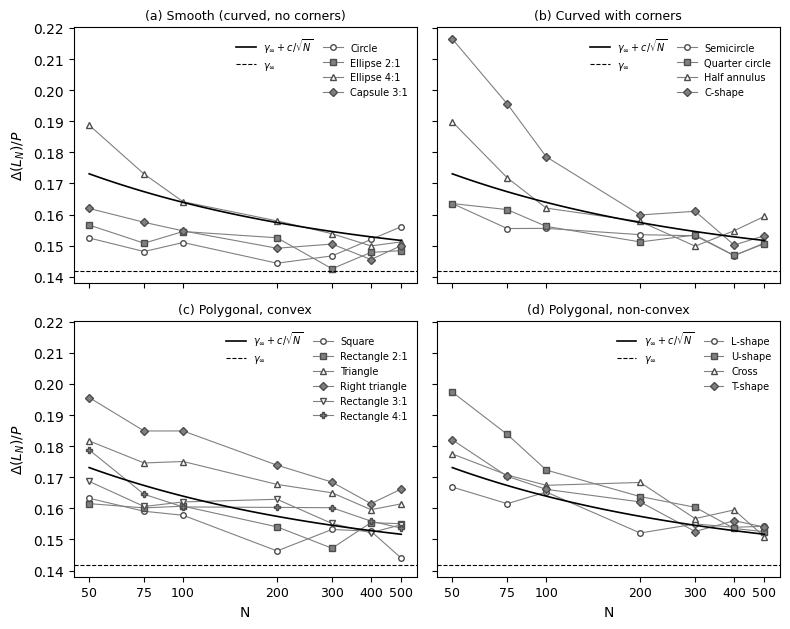

In [16]:

MK = ["o", "s", "^", "D", "v", "P"]
N_PLOT = [N for N in N_LIST if N >= 20]   # N = 10 はばらつきが大きいため除く
L_ext = {N: {k: np.array(v["L"]) for k, v in json.load(open(f"../output/results_N{N}.json"))["shapes"].items()} for N in N_LIST}

NN = np.geomspace(min(N_PLOT), max(N_PLOT), 100)
fig, axes = plt.subplots(2, 2, figsize=(8, 6.4), sharex=True, sharey=True)
for ax, (label, names) in zip(axes.flat, ROWS):
    for name, m in zip(names, MK):
        y = [(L_ext[N][name].mean() - L_ext[N]["Torus"].mean()) / SHAPES[name].length for N in N_PLOT]   # ΔL/P
        ax.plot(N_PLOT, y, color="0.5", lw=0.8, marker=m, ms=4, mfc="w" if name in CAL else "0.5", mec="0.3", label=name)
    l1, = ax.plot(NN, gamma_inf + c / np.sqrt(NN), color="k", lw=1.2)
    l2 = ax.axhline(gamma_inf, color="k", ls="--", lw=0.8)
    h, lab = ax.get_legend_handles_labels()
    blank = [plt.Line2D([], [], lw=0)] * (len(h) - 2)   # 左の列の残りを空欄で埋める
    ax.legend([l1, l2] + blank + h, [r"$\gamma_\infty + c/\sqrt{N}$", r"$\gamma_\infty$"] + [""] * len(blank) + lab,
              ncol=2, columnspacing=1.0, fontsize=7, frameon=False, loc="upper right")   # 左の列：推定式、右の列：図形
    ax.set_xscale("log")
    ax.set_xticks(N_PLOT, [str(n) for n in N_PLOT], fontsize=9)
    ax.set_xticks([], minor=True)
    ax.set_title(label.replace("\n", " "), fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("N")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\Delta (L_N) / P$")
plt.tight_layout()
plt.savefig("../output/fig3_boundary_term.pdf", dpi=300)
plt.show()

### 各モデルの推定精度（MAPE、maxAPE、平均巡回路長に対する誤差）


In [17]:
# Cavdar and Sokol
def cavdar_sokol(p, N):
    X = sample(p, 20000)
    x0, y0, x1, y1 = p.bounds
    cx, cy = np.abs(X[:, 0] - (x0 + x1) / 2), np.abs(X[:, 1] - (y0 + y1) / 2)
    A2 = (x1 - x0) * (y1 - y0)
    return 2.791 * np.sqrt(N * cx.std() * cy.std()) + 0.2669 * np.sqrt(N * X[:, 0].std() * X[:, 1].std() * A2 / (cx.mean() * cy.mean()))

# Choi et al. (2024)：β = D0·D1·D2·D3．D1 = 1（中心デポなし），D2 = 1（全領域）
def choi(N, A, S):
    D0 = 1.0580 * N ** -0.0616                  # 式 (4)（N > 8）
    D3 = S ** 0.0319 if 1 <= S <= 4 else 1.0    # 式 (7)：x は外接長方形の縦横比，1 ≤ x ≤ 4 以外は 1
    return D0 * D3 * np.sqrt(N * A)

prm = pd.read_csv("../output/table_parameters.csv").set_index(["model", "parameter"])["estimate"]   # キャリブレーション結果を読み込む
beta, gamma = prm["PC-Const", "beta"], prm["PC-Const", "gamma"]
gamma_inf, c = prm["PC-FN", "gamma_inf"], prm["PC-FN", "c"]
beta_cal = prm["BHH-R", "beta"]
kw = prm["KWON-R"][["k0", "k1 (N)", "k2 (S/N)"]].values
hs = prm["HS-R"][["h1 (sqrt N)", "h2 (S/sqrt N)", "h3 (const.)"]].values
ch = prm["CHOI-R"][["c0", "c1 (N exponent)", "c2 (S exponent)"]].values
display(prm.round(4))

def predict(p, N):
    A, P = p.area, p.length
    S, W = envelope(p)
    s = np.sqrt(N * A)
    return {
        "BHH": 0.7124 * s,
        "BHH-R": beta_cal * s,
        "KWON": (0.8326 - 0.0011 * N + 1.1147 * S / N) * s if N <= 80 else np.nan,
        "KWON-R": (kw[0] + kw[1] * N + kw[2] * S / N) * s,
        "CS": cavdar_sokol(p, N),
        "HS": (0.880 * np.sqrt(N) + 0.872 * S / np.sqrt(N) + 0.875) * np.sqrt(A) * 0.7124 / 0.8943,   # 直交距離 → ユークリッド距離（Johnson et al., 1996 の β の比）
        "HS-R": (hs[0] * np.sqrt(N) + hs[1] * S / np.sqrt(N) + hs[2]) * np.sqrt(A),
        "CHOI": choi(N, A, S),
        "CHOI-R": ch[0] * N ** ch[1] * (S ** ch[2] if 1 <= S <= 4 else 1.0) * s,
        "PC-Const": beta * s + gamma * P,
        "PC-FN": beta * s + (gamma_inf + c / np.sqrt(N)) * P,
    }

rng = np.random.default_rng(0)                  # CS の乱数を固定
rows = []
for N in N_LIST:
    for name, p in tqdm(SHAPES.items(), desc=f"N={N}"):
        L = L_all[N][name]
        pred = predict(p, N)
        pred["REF"] = L.mean()
        for m, v in pred.items():
            ape = np.abs(v - L) / L * 100
            rows.append({"N": N, "shape": name, "set": "Calibration" if name in CAL else "Validation", "model": m,
                         "ape_mean": ape.mean(), "ape_max": ape.max(), "bias": (v - L.mean()) / L.mean() * 100})
ape = pd.DataFrame(rows)
MODELS = list(ape.model.unique())


model     parameter      
PC-Const  beta               0.7128
          gamma              0.1654
PC-FN     gamma_inf          0.1418
          c                  0.2216
BHH-R     beta               0.7719
KWON-R    k0                 0.7883
          k1 (N)            -0.0001
          k2 (S/N)           0.7579
HS-R      h1 (sqrt N)        0.7098
          h2 (S/sqrt N)      0.3322
          h3 (const.)        0.7154
CHOI-R    c0                 0.9633
          c1 (N exponent)   -0.0432
          c2 (S exponent)    0.0066
Name: estimate, dtype: float64

N=500: 100%|███████████████████████████████████| 18/18 [01:01<00:00,  3.44s/it]


In [18]:
#for s in ["Calibration", "Validation"]:
for s in ["Calibration"]:
    t = ape[ape["set"] == s]
    print(f"{s} [MAPE, MaxAPE, Mean absolute error]")
    print(f"{s} MAPE:")
    display(t.groupby(["model", "N"]).ape_mean.mean().unstack()[N_LIST].loc[MODELS].round(2))
    
    print(f"{s} MaxAPE:")
    display(t.groupby(["model", "N"]).ape_max.max().unstack()[N_LIST].loc[MODELS].round(2))
    
    print(f"{s} Mean absolute error:")
    display(t.groupby(["model", "N"]).bias.apply(lambda x: x.mean()).unstack()[N_LIST].loc[MODELS[:-1]].round(2))
    
    print(f"{s} MAPE_sim:")
    display(t.groupby(["model", "N"]).bias.apply(lambda x: x.abs().mean()).unstack()[N_LIST].loc[MODELS[:-1]].round(2))

Calibration [MAPE, MaxAPE, Mean absolute error]
Calibration MAPE:


N,50,75,100,200,300,400,500
model,,,,,,,
BHH,13.45,10.81,9.37,6.62,5.39,4.66,4.15
BHH-R,6.76,4.26,3.04,2.06,2.61,3.32,3.85
KWON,4.27,4.02,NaN,NaN,NaN,NaN,NaN
KWON-R,4.21,3.19,2.75,2.12,1.60,1.22,1.37
CS,8.73,8.62,8.87,9.74,10.67,11.18,11.48
HS,4.00,3.17,2.71,1.91,1.65,1.53,1.47
HS-R,3.93,3.13,2.66,1.81,1.41,1.22,1.10
CHOI,4.46,4.11,3.72,2.46,1.87,1.87,2.11
CHOI-R,4.03,3.14,2.71,1.90,1.43,1.24,1.23


Calibration MaxAPE:


N,50,75,100,200,300,400,500
model,,,,,,,
BHH,27.11,22.28,19.07,12.83,10.32,9.37,8.38
BHH-R,21.03,15.79,14.13,11.58,8.90,8.53,8.72
KWON,21.09,16.54,NaN,NaN,NaN,NaN,NaN
KWON-R,20.67,16.44,16.05,11.32,7.21,4.91,5.50
CS,42.47,35.73,34.71,34.24,35.15,34.99,35.06
HS,23.02,16.53,14.99,8.96,6.40,5.95,5.66
HS-R,23.65,17.43,16.02,10.16,6.22,4.94,4.58
CHOI,25.74,19.85,19.23,10.35,7.87,6.54,7.21
CHOI-R,23.01,17.78,16.72,10.74,6.63,5.01,5.30


Calibration Mean absolute error:


N,50,75,100,200,300,400,500
model,,,,,,,
BHH,-13.60,-10.92,-9.44,-6.65,-5.41,-4.68,-4.17
BHH-R,-6.38,-3.48,-1.88,1.14,2.48,3.28,3.83
KWON,-0.86,-2.88,NaN,NaN,NaN,NaN,NaN
KWON-R,-1.77,-0.20,0.53,1.30,0.88,0.04,-1.00
CS,-1.32,1.88,3.63,6.74,8.23,9.10,9.68
HS,-0.01,-0.20,-0.45,-0.87,-1.03,-1.12,-1.17
HS-R,-0.20,0.08,0.08,0.03,-0.01,-0.04,-0.05
CHOI,2.29,2.86,2.73,1.47,0.28,-0.71,-1.54
CHOI-R,-1.06,0.24,0.64,0.68,0.24,-0.23,-0.66


Calibration MAPE_sim:


N,50,75,100,200,300,400,500
model,,,,,,,
BHH,13.60,10.92,9.44,6.65,5.41,4.68,4.17
BHH-R,6.38,3.48,2.04,1.27,2.48,3.28,3.83
KWON,2.73,2.88,NaN,NaN,NaN,NaN,NaN
KWON-R,2.29,1.71,1.49,1.48,0.98,0.58,1.00
CS,8.18,7.90,8.29,9.56,10.64,11.17,11.47
HS,2.24,1.67,1.34,1.02,1.06,1.12,1.17
HS-R,1.96,1.43,1.19,0.81,0.56,0.51,0.46
CHOI,2.84,3.09,2.90,1.85,1.39,1.64,1.91
CHOI-R,2.18,1.44,1.22,1.03,0.66,0.58,0.66


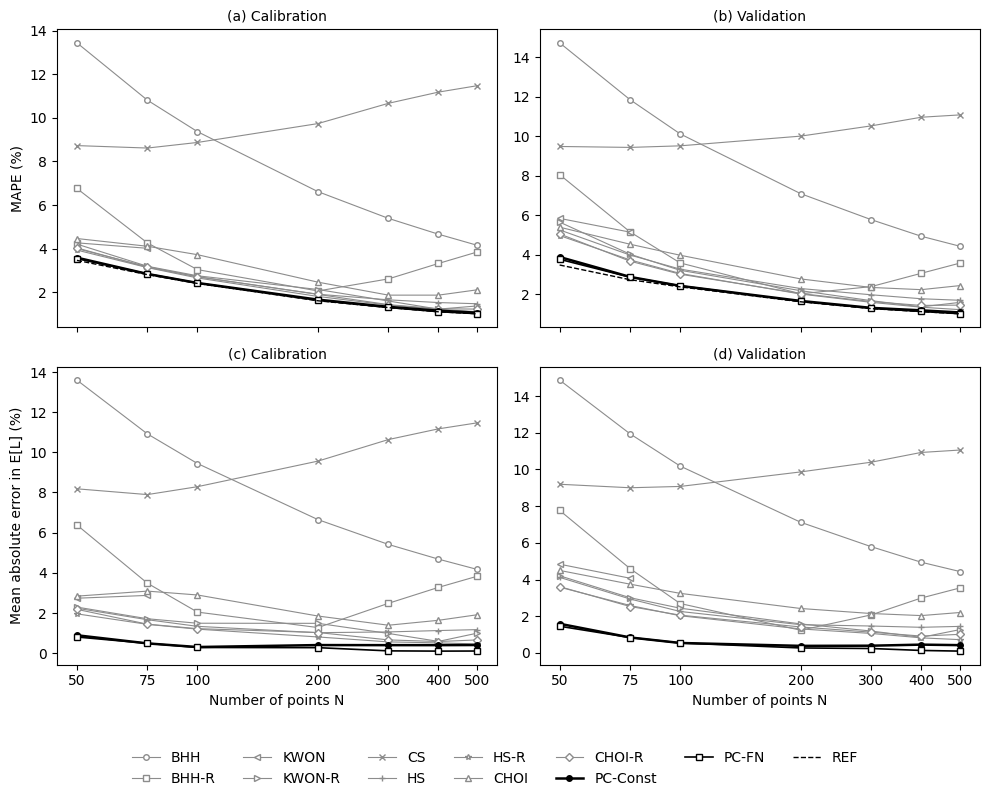

In [19]:
MARKERS = {"BHH": "o",
           "BHH-R": "s",
           "KWON": "<",
           "KWON-R": ">",
           "CS": "x",
           "HS": "+",
           "HS-R": "*",
           "CHOI": "^",
           "CHOI-R": "D",
          }

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True)
for j, s in enumerate(["Calibration", "Validation"]):
    t = ape[ape["set"] == s]
    stats = [t.groupby(["model", "N"]).ape_mean.mean().unstack()[N_LIST],
             t.groupby(["model", "N"]).bias.apply(lambda x: x.abs().mean()).unstack()[N_LIST]]
    for i, v in enumerate(stats):
        ax = axes[i, j]
        for m in MODELS:
            if m == "PC-Const":
                ax.plot(N_LIST, v.loc[m], color="k", lw=1.8, marker="o", ms=4, label=m)
            elif m == "PC-FN":
                ax.plot(N_LIST, v.loc[m], color="k", lw=1.2, marker="s", ms=4, mfc="w", label=m)
            elif m == "REF":
                if i == 0:
                    ax.plot(N_LIST, v.loc[m], color="k", ls="--", lw=1.0, label=m)
            else:
                ax.plot(N_LIST, v.loc[m], color="0.55", lw=0.8, marker=MARKERS[m], ms=4, mfc="w", label=m)
        ax.set_xscale("log")
        #ax.set_yscale("log")
        ax.set_xticks(N_LIST, [str(n) for n in N_LIST])
        ax.set_xticks([], minor=True)
        ax.set_title(f"({'ab'[j] if i == 0 else 'cd'[j]}) {s}", fontsize=10)
    axes[1, j].set_xlabel("Number of points N")
axes[0, 0].set_ylabel("MAPE (%)")
axes[1, 0].set_ylabel("Mean absolute error in E[L] (%)")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=7, frameon=False, fontsize=10)
plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.savefig("../output/fig4_mape_shapes.png", dpi=300)
plt.savefig("../output/fig4_mape_shapes.pdf", dpi=300)
plt.show()

In [20]:
display(ape[(ape["model"] == "CHOI") & (ape["set"] == "Validation")].pivot_table(index="shape", columns="N", values="bias").round(2))
display(ape[(ape["model"] == "CHOI-R") & (ape["set"] == "Validation")].pivot_table(index="shape", columns="N", values="bias").round(2))

N,50,75,100,200,300,400,500
shape,,,,,,,
C-shape,-7.53,-4.66,-2.99,-2.28,-3.19,-3.51,-4.28
Capsule 3:1,6.13,6.14,5.91,4.34,2.84,1.88,0.86
Ellipse 2:1,6.40,6.18,5.43,3.47,2.25,0.92,-0.02
Quarter circle,3.09,2.82,2.69,1.02,-0.51,-1.43,-2.41
Rectangle 2:1,4.91,4.69,4.29,2.85,1.67,0.32,-0.53
Rectangle 4:1,3.49,4.84,5.00,3.72,2.54,1.74,1.02
Right triangle,-1.82,-0.69,-0.68,-1.11,-1.98,-2.66,-3.55
T-shape,-2.35,-0.99,-0.66,-1.38,-2.02,-3.03,-3.69
U-shape,-4.74,-2.71,-1.57,-1.61,-2.31,-2.82,-3.46


N,50,75,100,200,300,400,500
shape,,,,,,,
C-shape,-9.53,-6.03,-3.88,-1.94,-2.13,-1.93,-2.31
Capsule 3:1,0.99,1.74,2.06,1.84,1.12,0.71,0.11
Ellipse 2:1,2.28,2.84,2.64,2.03,1.58,0.79,0.26
Quarter circle,0.85,1.34,1.75,1.37,0.59,0.19,-0.40
Rectangle 2:1,0.85,1.39,1.53,1.42,1.00,0.19,-0.25
Rectangle 4:1,-2.24,-0.23,0.45,0.50,0.10,-0.15,-0.45
Right triangle,-3.96,-2.12,-1.59,-0.76,-0.90,-1.07,-1.57
T-shape,-4.47,-2.41,-1.57,-1.04,-0.94,-1.45,-1.71
U-shape,-7.33,-4.65,-3.02,-1.81,-1.79,-1.78,-2.03


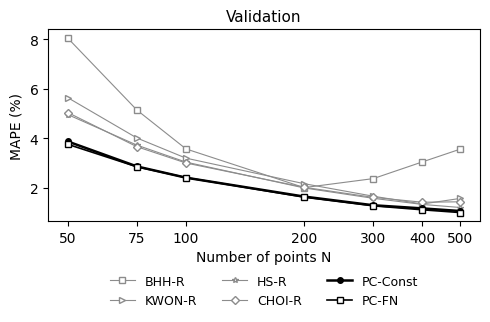

In [21]:

# 表示するモデル
PLOT_MODELS = [
    "BHH-R", "KWON-R", "HS-R", "CHOI-R",
    "PC-Const", "PC-FN"
]

MARKERS = {
    "BHH-R": "s",
    "KWON-R": ">",
    "HS-R": "*",
    "CHOI-R": "D",
}

# Validation の MAPE のみ抽出
t = ape[ape["set"] == "Validation"]
v = (
    t.groupby(["model", "N"]).ape_mean.mean()
    .unstack()[N_LIST]
)

fig, ax = plt.subplots(figsize=(5, 3.5))

for m in PLOT_MODELS:
    if m == "PC-Const":
        ax.plot(N_LIST, v.loc[m], color="k", lw=1.8,
                marker="o", ms=4, label=m)
    elif m == "PC-FN":
        ax.plot(N_LIST, v.loc[m], color="k", lw=1.2,
                marker="s", ms=4, mfc="w", label=m)
    else:
        ax.plot(N_LIST, v.loc[m], color="0.55", lw=0.8,
                marker=MARKERS[m], ms=4, mfc="w", label=m)

ax.set_xscale("log")
ax.set_xticks(N_LIST, [str(n) for n in N_LIST])
ax.set_xticks([], minor=True)

ax.set_xlabel("Number of points N")
ax.set_ylabel("MAPE (%)")
ax.set_title("Validation", fontsize=11)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False,
    fontsize=9
)

plt.tight_layout()

plt.show()


### トーラスのイメージ図を作成

In [22]:

N_FIG = 50
rng_figure = np.random.default_rng(3)
X = rng_figure.random((N_FIG, 2))
a = np.sqrt(1 / N_FIG)

def tour_for_figure(D):
    M = np.rint(D * SCALE).astype(int)
    problem = ("TYPE : TSP\n" f"DIMENSION : {len(D)}\n" "EDGE_WEIGHT_TYPE : EXPLICIT\n" "EDGE_WEIGHT_FORMAT : FULL_MATRIX\n"
               "EDGE_WEIGHT_SECTION\n" + "\n".join(" ".join(map(str, row)) for row in M) + "\n")
    t = np.array(_elkai.solve_problem("RUNS = 5\nMAX_TRIALS = 1000\nPROBLEM_FILE = :stdin:\n", problem)) - 1
    return np.append(t, t[0])

diff = X[:, None] - X[None]
D_euc = np.sqrt((diff ** 2).sum(-1))
wrap = diff - np.round(diff)                     # 最小像（トーラス上の変位）
D_tor = np.sqrt((wrap ** 2).sum(-1))
t_tor, t_euc = tour_for_figure(D_tor), tour_for_figure(D_euc)
L_tor = D_tor[t_tor[:-1], t_tor[1:]].sum()
L_euc = D_euc[t_euc[:-1], t_euc[1:]].sum()
print(f"L_torus = {L_tor:.3f}, L_square = {L_euc:.3f}, BHH = {0.7124 * np.sqrt(N):.3f}")



L_torus = 5.377, L_square = 5.712, BHH = 15.930


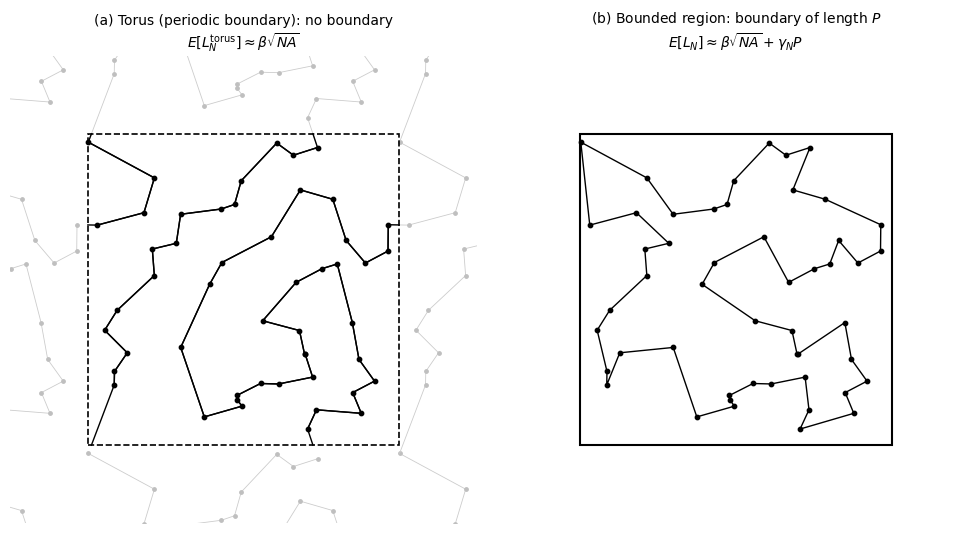

In [23]:
cell = box(0, 0, 1, 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 5.6))

# (a) トーラス：周期境界（周囲の複製を薄く表示し、中央のセルでは辺を境界で切って表示）
ax = axes[0]
for sx in (-1, 0, 1):
    for sy in (-1, 0, 1):
        if (sx, sy) == (0, 0):
            continue
        for i, j in zip(t_tor[:-1], t_tor[1:]):
            p = X[i] + (sx, sy)
            q = p - wrap[i, j]
            ax.plot([p[0], q[0]], [p[1], q[1]], color="0.8", lw=0.6, zorder=1)
        ax.scatter(X[:, 0] + sx, X[:, 1] + sy, s=6, color="0.75", zorder=1)
for i, j in zip(t_tor[:-1], t_tor[1:]):
    for p, d in [(X[i], -wrap[i, j]), (X[j], wrap[i, j])]:   # 両端から辺を延ばし、セル内の部分だけを描く
        seg = LineString([p, p + d]).intersection(cell)
        if not seg.is_empty and seg.length > 0:
            x, y = seg.xy
            ax.plot(x, y, color="k", lw=1.0, zorder=2)
ax.scatter(X[:, 0], X[:, 1], s=10, color="k", zorder=3)
ax.add_patch(Rectangle((0, 0), 1, 1, fill=False, ls="--", lw=1.2, ec="k", zorder=4))
ax.set_title("(a) Torus (periodic boundary): no boundary\n" + r"$E[L_N^{\mathrm{torus}}] \approx \beta\sqrt{NA}$", fontsize=10)

# (b) 正方形：境界あり
ax = axes[1]
#ax.add_patch(Rectangle((0, 0), 1, 1, color="0.87", lw=0, zorder=0))
ax.add_patch(Rectangle((a / 2, a / 2), 1 - a, 1 - a, color="w", lw=0, zorder=0))
ax.plot(X[t_euc, 0], X[t_euc, 1], color="k", lw=1.0, zorder=2)
ax.scatter(X[:, 0], X[:, 1], s=10, color="k", zorder=3)
ax.add_patch(Rectangle((0, 0), 1, 1, fill=False, lw=1.5, ec="k", zorder=4))
#ax.annotate("", xy=(1.0, 0.5), xytext=(1 - a / 2, 0.5), arrowprops=dict(arrowstyle="<->", lw=0.8, shrinkA=0, shrinkB=0), zorder=5)
#ax.text(1.03, 0.5, r"$a/2$", va="center", fontsize=9)
#（境界から a/2 以内の帯を表示）
#ax.text(0.5, -0.1, r"shaded: boundary layer within $a/2$ of the boundary ($a = \sqrt{A/N}$)", ha="center", fontsize=8)
ax.set_title("(b) Bounded region: boundary of length $P$\n" + r"$E[L_N] \approx \beta\sqrt{NA} + \gamma_N P$", fontsize=10)
for ax in axes:
    ax.set_xlim(-0.25, 1.25); ax.set_ylim(-0.25, 1.25)
    ax.set_aspect("equal"); ax.axis("off")
#fig.text(0.5, 0.04, r"Boundary increment: $\Delta L = E[L_N] - E[L_N^{\mathrm{torus}}] \approx \gamma_N P$" + f"   (same {N} points in both panels)",ha="center", fontsize=9.5)
plt.tight_layout(rect=[0, 0.07, 1, 0.97])
plt.savefig("../output/fig1_torus_schematic.png", dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.savefig("../output/fig1_torus_schematic.pdf", dpi=300, bbox_inches="tight", pad_inches=0.05)
plt.show()

## Small-N stress test と残差の確認（N = 10, 20, 30, 40 を追加）

S_P = P/√A（周長指標）。S_P/√N = P/√(NA) は、境界から a/2 以内の帯が面積に占める割合の約 2 倍。
係数（β, γ, γ∞, c）は N = 50–500 の Calibration で推定した値をそのまま使う（N = 10–40 は N について推定範囲外）。

In [24]:
N_SMALL = [10, 20, 30, 40]
REPS_SMALL = 1000

In [25]:
rng = np.random.default_rng(1)
for N in N_SMALL:
    filename = f"../output/results_N{N}.json"
    if os.path.exists(filename):
        print(f"{filename} exists")
    else:
        res = {"N": N, "shapes": {}}
        res["shapes"]["Torus"] = {"P": None, "L": [tour_length(dist_torus(rng.random((N, 2)))) for _ in range(REPS_SMALL)]}
        for name, p in tqdm(SHAPES.items(), total=len(SHAPES), desc=f"N={N}"):
            res["shapes"][name] = {"P": p.length, "L": [tour_length(dist_euclid(sample(p, N))) for _ in range(REPS_SMALL)]}
        json.dump(res, open(filename, "w"))
    

../output/results_N10.json exists
../output/results_N20.json exists
../output/results_N30.json exists
../output/results_N40.json exists


In [26]:
L_small = {N: {k: np.array(v["L"]) for k, v in json.load(open(f"../output/results_N{N}.json"))["shapes"].items()} for N in N_SMALL}
rng = np.random.default_rng(0)                  # CS の乱数を固定
rows = []
for N in N_SMALL:
    for name, p in tqdm(SHAPES.items(), desc=f"N={N}"):
        L = L_small[N][name]
        pred = predict(p, N)
        pred["REF"] = L.mean()
        for m, v in pred.items():
            e = np.abs(v - L) / L * 100
            rows.append({"N": N, "shape": name, "set": "Calibration" if name in CAL else "Validation", "model": m,
                         "ape_mean": e.mean(), "ape_max": e.max(), "bias": (v - L.mean()) / L.mean() * 100})
ape_small = pd.DataFrame(rows)
ape_all = pd.concat([ape_small, ape], ignore_index=True)
N_ALL = sorted(set(N_SMALL + N_LIST))


N=40: 100%|████████████████████████████████████| 18/18 [00:51<00:00,  2.87s/it]


In [27]:

for s in ["Validation"]:
    t = ape_all[ape_all["set"] == s]
    print(f"{s} MAPE:")
    display(t.groupby(["model", "N"]).ape_mean.mean().unstack().loc[MODELS, N_SMALL].round(2))   # MAPE
    print(f"{s} Mean absolute error:")
    display(t.groupby(["model", "N"]).bias.apply(lambda x: x.mean()).unstack().loc[MODELS, N_SMALL].round(2))   # E[L] の平均絶対誤差

Validation MAPE:


N,10,20,30,40
model,,,,
BHH,30.28,23.09,19.02,16.50
BHH-R,24.85,16.88,12.52,9.88
KWON,13.65,9.28,7.61,6.52
KWON-R,14.49,10.20,7.98,6.58
CS,22.17,14.26,10.94,9.86
HS,12.47,8.33,6.84,5.88
HS-R,11.87,8.09,6.54,5.59
CHOI,13.68,8.33,6.59,5.80
CHOI-R,16.79,10.29,7.43,5.95


Validation Mean absolute error:


N,10,20,30,40
model,,,,
BHH,-31.11,-23.47,-19.27,-16.68
BHH-R,-25.36,-17.08,-12.54,-9.73
KWON,-1.28,-2.09,-1.75,-1.85
KWON-R,-10.77,-8.19,-5.85,-4.30
CS,-21.84,-13.28,-8.53,-5.45
HS,1.12,-1.20,-1.38,-1.44
HS-R,-3.74,-3.34,-2.49,-1.99
CHOI,-9.92,-4.09,-1.32,0.06
CHOI-R,-15.42,-8.81,-5.48,-3.66


In [28]:
V = ape[(ape["set"] == "Validation") & (ape["N"] >= 50)]
NS = sorted(V["N"].unique())
mape_vn = V.pivot_table(index="model", columns="N", values="ape_mean").reindex(MODELS)[NS]                       # 検証領域の MAPE の平均
mpe_vn = V.pivot_table(index="model", columns="N", values="bias").reindex([m for m in MODELS if m != "REF"])[NS]   # 検証領域の PE の平均（符号付き、REF は常に 0 なので除く）
tab_vn = pd.concat([mape_vn, mpe_vn], keys=["MAPE", "Mean PE"], names=["Metric", "Model"])
display(tab_vn.round(2))
tab_vn.round(2).to_csv("../output/table_validation_over_N50.csv")


N                   50     75     100    200    300    400    500
Metric  Model                                                    
MAPE    BHH       14.73  11.84  10.11   7.08   5.77   4.93   4.42
        BHH-R      8.05   5.14   3.57   2.01   2.38   3.05   3.57
        KWON       5.83   5.13    NaN    NaN    NaN    NaN    NaN
        KWON-R     5.64   4.02   3.20   2.17   1.66   1.35   1.58
        CS         9.47   9.43   9.51  10.00  10.52  10.96  11.07
        HS         5.25   3.97   3.26   2.28   1.96   1.76   1.68
        HS-R       4.96   3.73   3.04   2.00   1.58   1.33   1.21
        CHOI       5.39   4.52   3.97   2.77   2.33   2.22   2.43
        CHOI-R     5.04   3.66   3.01   2.02   1.62   1.42   1.44
        PC-Const   3.88   2.87   2.41   1.65   1.30   1.17   1.07
        PC-FN      3.76   2.85   2.42   1.63   1.28   1.12   1.00
        REF        3.47   2.73   2.36   1.61   1.26   1.11   1.00
Mean PE BHH      -14.87 -11.94 -10.19  -7.12  -5.79  -4.94  -4.43
        BHH-R     -7.77  -4.59  -2.69   0.63   2.07   2.99   3.54
        KWON      -2.24  -3.94    NaN    NaN    NaN    NaN    NaN
        KWON-R    -3.17  -1.31  -0.27   0.80   0.48  -0.23  -1.27
        CS        -3.42  -0.07   1.96   5.63   7.14   8.02   8.61
        HS        -1.44  -1.32  -1.25  -1.36  -1.42  -1.39  -1.44
        HS-R      -1.65  -1.06  -0.74  -0.47  -0.41  -0.32  -0.33
        CHOI       0.84   1.74   1.94   1.00  -0.08  -0.95  -1.78
        CHOI-R    -2.51  -0.90  -0.18   0.18  -0.15  -0.50  -0.93
        PC-Const  -1.36  -0.50  -0.06   0.30   0.37   0.45   0.42
        PC-FN     -0.74  -0.37  -0.16  -0.05  -0.03   0.04   0.02

In [29]:
V_s = ape_all[(ape_all["set"] == "Validation") & (ape_all["N"] < 50)]
NS_s = sorted(V_s["N"].unique())
mape_vn_s = V_s.pivot_table(index="model", columns="N", values="ape_mean").reindex(MODELS)[NS_s]                       # 検証領域の MAPE の平均
mpe_vn_s = V_s.pivot_table(index="model", columns="N", values="bias").reindex([m for m in MODELS if m != "REF"])[NS_s]   # 検証領域の PE の平均（符号付き）
tab_vn_s = pd.concat([mape_vn_s, mpe_vn_s], keys=["MAPE", "Mean PE"], names=["Metric", "Model"])
display(tab_vn_s.round(2))
tab_vn_s.round(2).to_csv("../output/table_validation_by_N_small.csv")

N                    10     20     30     40
Metric  Model                               
MAPE    BHH       30.28  23.09  19.02  16.50
        BHH-R     24.85  16.88  12.52   9.88
        KWON      13.65   9.28   7.61   6.52
        KWON-R    14.49  10.20   7.98   6.58
        CS        22.17  14.26  10.94   9.86
        HS        12.47   8.33   6.84   5.88
        HS-R      11.87   8.09   6.54   5.59
        CHOI      13.68   8.33   6.59   5.80
        CHOI-R    16.79  10.29   7.43   5.95
        PC-Const  11.59   7.20   5.37   4.45
        PC-FN     10.50   6.35   4.94   4.22
        REF        9.82   5.80   4.53   3.88
Mean PE BHH      -31.11 -23.47 -19.27 -16.68
        BHH-R    -25.36 -17.08 -12.54  -9.73
        KWON      -1.28  -2.09  -1.75  -1.85
        KWON-R   -10.77  -8.19  -5.85  -4.30
        CS       -21.84 -13.28  -8.53  -5.45
        HS         1.12  -1.20  -1.38  -1.44
        HS-R      -3.74  -3.34  -2.49  -1.99
        CHOI      -9.92  -4.09  -1.32   0.06
        CHOI-R   -15.42  -8.81  -5.48  -3.66
        PC-Const  -6.80  -4.33  -2.77  -1.91
        PC-FN      0.01  -1.35  -1.10  -0.90

In [31]:
E = ape[ape["N"] >= 50]
MODELS_PE = [m for m in MODELS if m != "REF" and E.loc[E["model"] == m, "bias"].notna().all()]   # KWON（N ≤ 80 のみ）と REF（常に 0）は除く
MODELS_MAPE = MODELS_PE + ["REF"]
ORDER = list(VAL)

pe = E.pivot_table(index="shape", columns="model", values="bias").loc[ORDER, MODELS_PE]           # PE：region–N ごとの符号付き誤差を N について平均
mape = E.pivot_table(index="shape", columns="model", values="ape_mean").loc[ORDER, MODELS_MAPE]   # MAPE：N について平均（各 N の試行回数が同じならインスタンス全体の MAPE と一致）
e = E[E["shape"].isin(ORDER)]
pe.loc["Mean |PE|"] = e.groupby("model")["bias"].apply(lambda x: x.abs().mean())[MODELS_PE]      # 全 region–N の |PE| の平均
mape.loc["Mean"] = e.groupby("model")["ape_mean"].mean()[MODELS_MAPE]
for d in [pe, mape]:
    d.insert(0, "P", [SHAPES[k].length if k in SHAPES else np.nan for k in d.index])
pe.round(2).to_csv("../output/table_pe_region.csv")
mape.round(2).to_csv("../output/table_mape_region.csv")
E.pivot_table(index=["shape", "N"], columns="model", values="bias").loc[ORDER, MODELS_PE].round(2).to_csv("../output/table_pe_region_N.csv")   # region–N ごとの PE（全組み合わせ）

display(mape.round(2).T)
display(pe.round(2).T)

shape,Ellipse 2:1,Capsule 3:1,Quarter circle,C-shape,Rectangle 2:1,Right triangle,Rectangle 4:1,U-shape,T-shape,Mean
model,,,,,,,,,,
P,3.87,4.28,4.03,6.07,4.24,4.83,5.00,5.94,5.37,NaN
BHH,6.31,7.05,6.75,11.08,7.11,9.03,8.58,10.53,9.25,8.41
BHH-R,3.55,3.47,3.55,5.27,3.49,3.98,3.68,4.75,3.98,3.97
KWON-R,2.55,2.51,2.16,4.40,2.25,2.75,2.13,3.67,2.81,2.80
CS,3.54,5.46,4.09,22.01,7.27,18.29,8.81,4.78,16.98,10.14
HS,2.26,2.24,2.03,4.84,2.14,3.04,2.14,4.12,3.12,2.88
HS-R,2.40,2.15,2.07,4.02,2.10,2.46,1.89,3.40,2.47,2.55
CHOI,3.86,4.20,2.66,4.16,3.20,2.85,3.48,3.13,2.83,3.37
CHOI-R,2.49,2.21,2.11,4.06,2.17,2.51,1.96,3.39,2.53,2.60


shape,Ellipse 2:1,Capsule 3:1,Quarter circle,C-shape,Rectangle 2:1,Right triangle,Rectangle 4:1,U-shape,T-shape,Mean |PE|
model,,,,,,,,,,
P,3.87,4.28,4.03,6.07,4.24,4.83,5.00,5.94,5.37,NaN
BHH,-6.36,-7.10,-6.81,-11.14,-7.18,-9.10,-8.64,-10.59,-9.31,8.47
BHH-R,1.45,0.65,0.97,-3.72,0.57,-1.51,-1.02,-3.12,-1.75,3.56
KWON-R,1.76,1.71,0.49,-4.25,0.86,-2.02,0.75,-3.46,-2.25,2.08
CS,1.39,-5.49,2.25,21.94,-7.33,18.20,-8.87,-3.13,16.89,9.93
HS,1.08,0.97,-0.13,-4.87,0.19,-2.63,-0.05,-4.09,-2.86,2.16
HS-R,1.68,1.20,0.85,-3.93,0.79,-1.68,-0.17,-3.23,-1.91,1.73
CHOI,3.52,4.01,0.76,-4.06,2.60,-1.78,3.19,-2.75,-2.02,2.90
CHOI-R,1.77,1.22,0.81,-3.96,0.88,-1.71,-0.29,-3.20,-1.94,1.81
